In [29]:
from __future__ import annotations
import importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from kde_tools.gaussian_mixtures import exact_mixture_mise_values

In [30]:
def print_matrix(M):
    print(pd.DataFrame(D2).to_string(index=False, header=False, float_format=lambda x: f"{x:.4f}"))

In [31]:
def squared_l2_distance_from_gram(gram: np.ndarray) -> np.ndarray:
    diagonal = np.diag(gram)
    return np.maximum(diagonal[:, None] + diagonal[None, :] - 2.0 * gram, 0.0)

In [32]:
def exact_gaussian_kde_l2_gram(
        samples: np.ndarray,
        h_grid: np.ndarray,
) -> np.ndarray:
    samples = np.asarray(samples, dtype=float)
    h_grid = np.asarray(h_grid, dtype=float)
    n = len(samples)
    squared_differences = (samples[:, None] - samples[None, :]) ** 2
    gram = np.empty((len(h_grid), len(h_grid)), dtype=float)
    N = len(h_grid)
    for i in range(N):
        for j in range(i, N):
            h_i = h_grid[i]
            h_j = h_grid[j]
            variance = h_i**2 + h_j**2
            value = np.exp(-squared_differences / (2.0 * variance)).sum()
            value /= n**2 * np.sqrt(2.0 * np.pi * variance)
            gram[i, j] = value
            gram[j, i] = value
    return gram

In [33]:
def beta2_divergence_matrix(
        samples: np.ndarray,
        h_grid: np.ndarray,
) -> np.ndarray:
    gram = exact_gaussian_kde_l2_gram(samples=samples, h_grid=h_grid)
    return 0.5 * squared_l2_distance_from_gram(gram=gram)

In [34]:
def beta2_similarity_matrix(
        samples: np.ndarray,
        h_grid: np.ndarray,
        tau: float = 1.0,
) -> np.ndarray:
    if tau <= 0.0:
        raise ValueError("tau must be positive.")
    divergence = beta2_divergence_matrix(samples=samples, h_grid=h_grid)
    similarity = np.exp(-float(tau) * divergence)
    np.fill_diagonal(a=similarity, val=1.0)
    return similarity

In [64]:
rng = np.random.default_rng(12345)
n = 200
N = 200
tau = 1.0
samples = rng.normal(loc=0.0, scale=1.0, size=n)
h_grid = np.geomspace(start=0.1, stop=1.0, num=N)
# print(h_grid)
D2 = beta2_divergence_matrix(samples=samples, h_grid=h_grid)
SimMatr = beta2_similarity_matrix(samples=samples, h_grid=h_grid, tau=tau)
# print()
# print_matrix(D2)
# print()
# print_matrix(SimMatr)

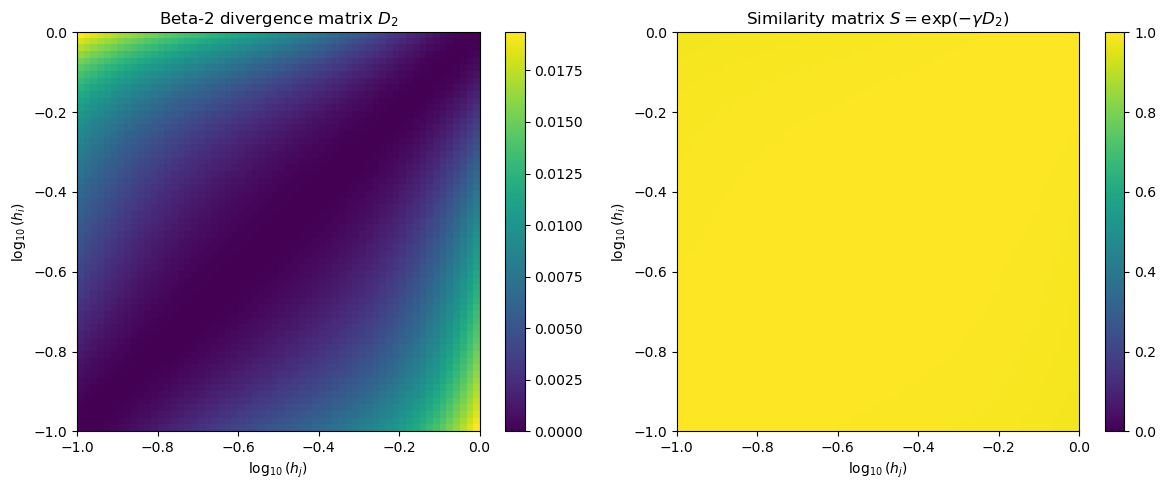

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

extent = [
    np.log10(h_grid[0]),
    np.log10(h_grid[-1]),
    np.log10(h_grid[0]),
    np.log10(h_grid[-1]),
]

image_d2 = axes[0].imshow(
    D2,
    origin="lower",
    aspect="auto",
    extent=extent,
    cmap="viridis",
)
axes[0].set_title(r"Beta-2 divergence matrix $D_2$")
axes[0].set_xlabel(r"$\log_{10}(h_j)$")
axes[0].set_ylabel(r"$\log_{10}(h_i)$")
fig.colorbar(image_d2, ax=axes[0])

image_similarity = axes[1].imshow(
    SimMatr,
    origin="lower",
    aspect="auto",
    extent=extent,
    cmap="viridis",
    vmin=0.0,
    vmax=1.0,
)
axes[1].set_title(r"Similarity matrix $S=\exp(-\gamma D_2)$")
axes[1].set_xlabel(r"$\log_{10}(h_j)$")
axes[1].set_ylabel(r"$\log_{10}(h_i)$")
fig.colorbar(image_similarity, ax=axes[1])

plt.tight_layout()
plt.show()

In [37]:
def perron_vector(matrix: np.ndarray) -> np.ndarray:
    matrix = np.asarray(matrix, dtype=float)
    if matrix.ndim != 2 or matrix.shape[0] != matrix.shape[1]:
        raise ValueError("The matrix must be square.")
    if not np.allclose(matrix, matrix.T, atol=1e-12):
        raise ValueError("The matrix must be symmetric.")
    if np.any(matrix < 0):
        raise ValueError("The matrix must be nonnegative.")

    eigenvalues, eigenvectors = np.linalg.eigh(matrix)
    vector = eigenvectors[:, int(np.argmax(eigenvalues))]
    if np.sum(vector) < 0:
        vector = -vector
    return vector / np.sum(vector)

In [38]:
vec = perron_vector(matrix=SimMatr)
print(vec)

[0.01662285 0.01662856 0.01663396 0.01663905 0.01664383 0.01664829
 0.01665243 0.01665627 0.01665981 0.01666306 0.01666603 0.01666876
 0.01667124 0.0166735  0.01667556 0.01667744 0.01667916 0.01668072
 0.01668215 0.01668345 0.01668463 0.0166857  0.01668667 0.01668754
 0.01668832 0.016689   0.01668959 0.01669009 0.01669051 0.01669083
 0.01669107 0.01669122 0.01669128 0.01669124 0.01669111 0.01669086
 0.0166905  0.01669    0.01668936 0.01668854 0.01668754 0.01668631
 0.01668483 0.01668307 0.01668098 0.01667853 0.01667566 0.01667233
 0.01666847 0.01666404 0.01665897 0.0166532  0.01664667 0.0166393
 0.01663103 0.01662179 0.01661151 0.01660013 0.0165876  0.01657384]


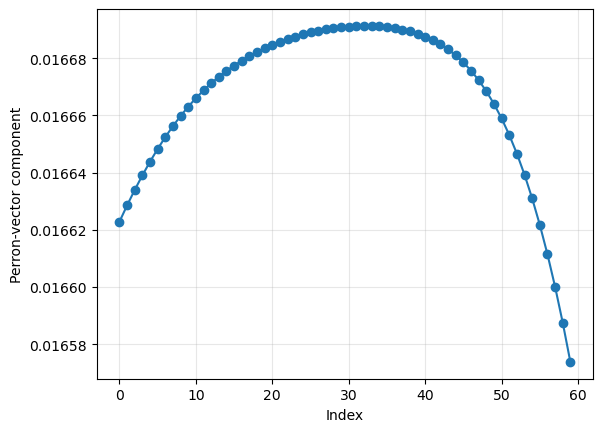

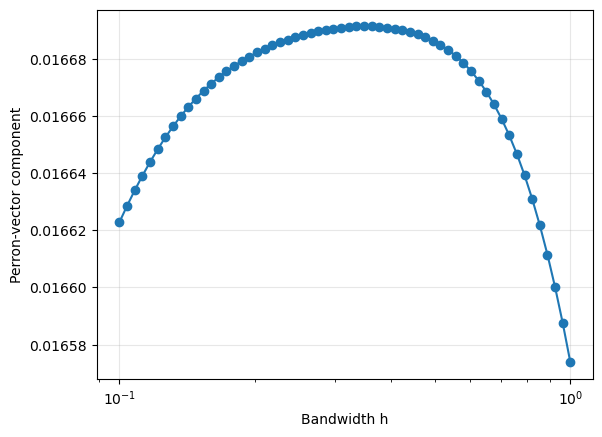

In [39]:
plt.plot(vec, marker="o")
plt.xlabel("Index")
plt.ylabel("Perron-vector component")
plt.grid(alpha=0.3)
plt.show()

plt.plot(h_grid, vec, marker="o")
plt.xscale("log")  # appropriate for a geometric bandwidth grid
plt.xlabel("Bandwidth h")
plt.ylabel("Perron-vector component")
plt.grid(alpha=0.3)
plt.show()

In [40]:
def spectral_choice_from_similarity(
        similarity_matrix: np.ndarray,
) -> dict[str, np.ndarray | int | float]:
    vector = perron_vector(matrix=similarity_matrix)
    return {
        "selected_index": int(np.argmax(vector)),
        "perron_vector": vector,
        "selected_weight": float(np.max(vector)),
    }

Plot the ISE($h$)-curve

In [41]:
def exact_oracle_ise_values(
        samples: np.ndarray,
        h_grid: np.ndarray,
        sigma2: float = 1.0,
) -> np.ndarray:
    samples = np.asarray(samples, dtype=float)
    h_grid = np.asarray(h_grid, dtype=float)
    sigma = float(np.sqrt(sigma2))
    n = len(samples)
    squared_differences = (samples[:, None] - samples[None, :]) ** 2
    kde_squared_integrals = []
    cross_integrals = []
    for h in h_grid:
        variance = 2.0 * h**2
        kde_squared = np.exp(-squared_differences / (2.0 * variance)).sum()
        kde_squared /= n**2 * np.sqrt(2.0 * np.pi * variance)
        kde_squared_integrals.append(kde_squared)

        variance = sigma2 + h**2
        cross = np.exp(-samples**2 / (2.0 * variance)).sum()
        cross /= n * np.sqrt(2.0 * np.pi * variance)
        cross_integrals.append(cross)
    true_squared_integral = 1.0 / (2.0 * np.sqrt(np.pi) * sigma)
    return (
        np.asarray(kde_squared_integrals)
        - 2.0 * np.asarray(cross_integrals)
        + true_squared_integral
    )

In [14]:
ise_values = exact_oracle_ise_values(samples, h_grid)

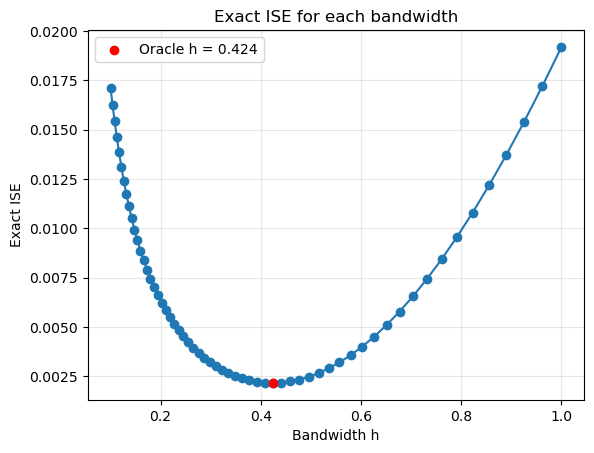

In [42]:
oracle_index = np.argmin(ise_values)

plt.plot(h_grid, ise_values, marker="o")
plt.scatter(
    h_grid[oracle_index],
    ise_values[oracle_index],
    color="red",
    label=f"Oracle h = {h_grid[oracle_index]:.3f}",
    zorder=3,
)
plt.xlabel("Bandwidth h")
plt.ylabel("Exact ISE")
plt.title("Exact ISE for each bandwidth")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [43]:
choice = spectral_choice_from_similarity(SimMatr)

spectral_index = choice["selected_index"]
spectral_h = h_grid[spectral_index]

ise_values = exact_oracle_ise_values(
    samples=samples,
    h_grid=h_grid,
    sigma2=1.0,
)

oracle_index = int(np.argmin(ise_values))
oracle_h = h_grid[oracle_index]

print(f"Spectral bandwidth: h = {spectral_h:.6f}")
print(f"Oracle bandwidth:   h = {oracle_h:.6f}")
print(f"Spectral ISE:       {ise_values[spectral_index]:.6f}")
print(f"Minimum ISE:        {ise_values[oracle_index]:.6f}")

Spectral bandwidth: h = 0.348637
Oracle bandwidth:   h = 0.423759
Spectral ISE:       0.002511
Minimum ISE:        0.002160


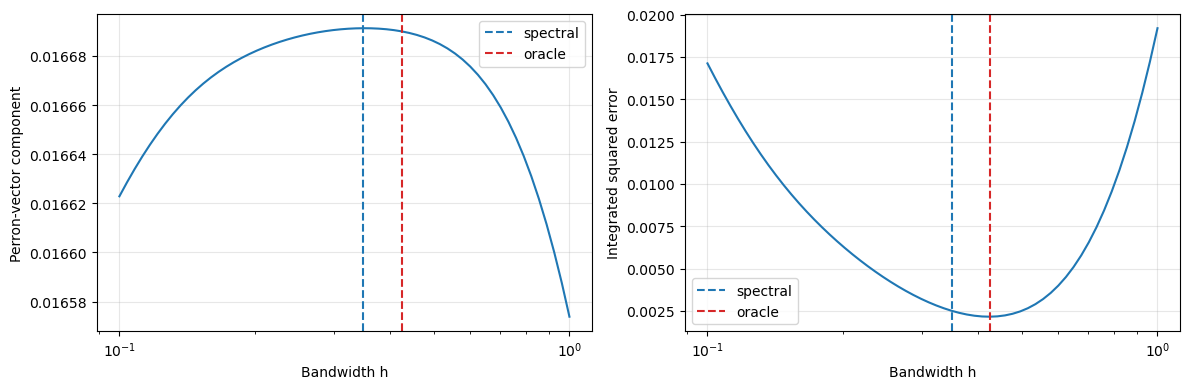

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(h_grid, choice["perron_vector"])
axes[0].axvline(
    spectral_h,
    color="tab:blue",
    linestyle="--",
    label="spectral",
)
axes[0].axvline(
    oracle_h,
    color="tab:red",
    linestyle="--",
    label="oracle",
)
axes[0].set_xscale("log")
axes[0].set_xlabel("Bandwidth h")
axes[0].set_ylabel("Perron-vector component")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(h_grid, ise_values)
axes[1].axvline(
    spectral_h,
    color="tab:blue",
    linestyle="--",
    label="spectral",
)
axes[1].axvline(
    oracle_h,
    color="tab:red",
    linestyle="--",
    label="oracle",
)
axes[1].set_xscale("log")
axes[1].set_xlabel("Bandwidth h")
axes[1].set_ylabel("Integrated squared error")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [45]:
ise_values = exact_oracle_ise_values(
    samples=samples,
    h_grid=h_grid,
    sigma2=1.0,
)

mise_values = exact_mixture_mise_values(
    n=len(samples),
    h_grid=h_grid,
    weights=np.array([1.0]),
    means=np.array([0.0]),
    sigmas=np.array([1.0]),
)

ise_index = int(np.argmin(ise_values))
mise_index = int(np.argmin(mise_values))

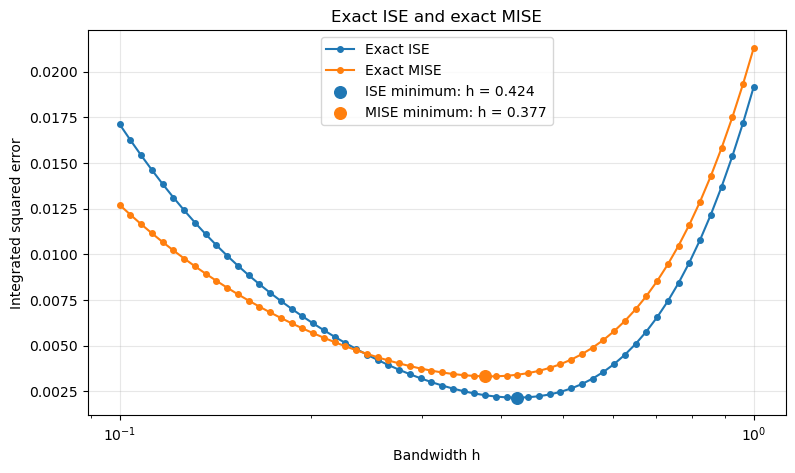

In [46]:
plt.figure(figsize=(9, 5))

plt.plot(
    h_grid,
    ise_values,
    marker="o",
    markersize=4,
    label="Exact ISE",
)

plt.plot(
    h_grid,
    mise_values,
    marker="o",
    markersize=4,
    label="Exact MISE",
)

plt.scatter(
    h_grid[ise_index],
    ise_values[ise_index],
    color="tab:blue",
    s=70,
    zorder=3,
    label=f"ISE minimum: h = {h_grid[ise_index]:.3f}",
)

plt.scatter(
    h_grid[mise_index],
    mise_values[mise_index],
    color="tab:orange",
    s=70,
    zorder=3,
    label=f"MISE minimum: h = {h_grid[mise_index]:.3f}",
)

plt.xscale("log")
plt.xlabel("Bandwidth h")
plt.ylabel("Integrated squared error")
plt.title("Exact ISE and exact MISE")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

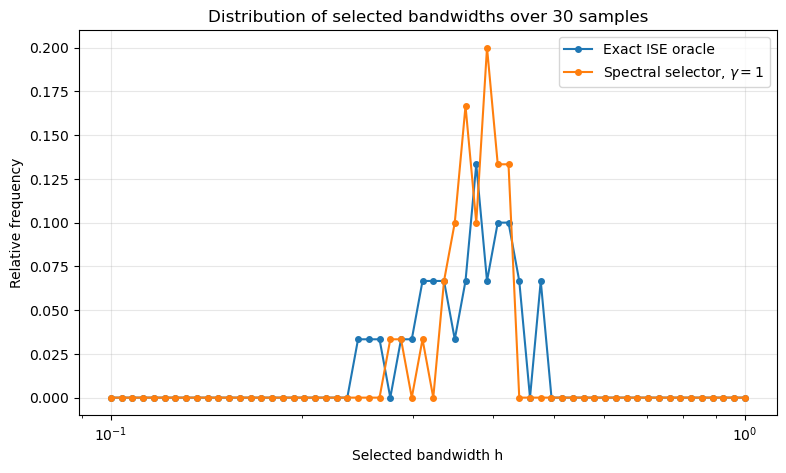

In [49]:
from kde_tools.experiments import run_one_spectral_vs_oracle_experiment

# Start with a small pilot run. Increase to 100 or more later.
R = 30
base_seed = 90_000
gamma = 1.0  # matches the value used above in 001

distribution_results = pd.DataFrame(
    [
        run_one_spectral_vs_oracle_experiment(
            seed=base_seed + repetition,
            n=n,
            sigma2=1.0,
            h_grid=h_grid,
            gamma=gamma,
        )
        for repetition in range(R)
    ]
)

oracle_frequencies = (
    np.bincount(
        distribution_results["oracle_index"].to_numpy(dtype=int),
        minlength=len(h_grid),
    )
    / R
)

spectral_frequencies = (
    np.bincount(
        distribution_results["spectral_index"].to_numpy(dtype=int),
        minlength=len(h_grid),
    )
    / R
)

plt.figure(figsize=(9, 5))

plt.plot(
    h_grid,
    oracle_frequencies,
    marker="o",
    markersize=4,
    label="Exact ISE oracle",
)

plt.plot(
    h_grid,
    spectral_frequencies,
    marker="o",
    markersize=4,
    label=rf"Spectral selector, $\gamma={gamma:g}$",
)

plt.xscale("log")
plt.xlabel("Selected bandwidth h")
plt.ylabel("Relative frequency")
plt.title(f"Distribution of selected bandwidths over {R} samples")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [53]:
def select_spectral_bandwidth(
        samples: np.ndarray,
        h_grid: np.ndarray,
        gamma: float = 1.0,
) -> dict[str, np.ndarray | int]:
    gamma = float(gamma)
    if not np.isfinite(gamma) or gamma <= 0.0:
        raise ValueError("gamma must be finite and strictly positive.")
    d2 = beta2_divergence_matrix(samples=samples, h_grid=h_grid)
    similarity = np.exp(-gamma * d2)
    np.fill_diagonal(similarity, 1.0)
    vector = perron_vector(matrix=similarity)
    return {
        "selected_index": int(np.argmax(vector)),
        "perron_vector": vector,
        "similarity_matrix": similarity,
        "beta2_divergence": d2,
    }

In [54]:
def exact_beta2_bandwidth_selection_counts(
    n: int,
    h_grid: np.ndarray,
    M: int,
    sigma2: float = 1.0,
    tau: float = 1.0,
    seed: int | None = None,
) -> np.ndarray:
    """Count exact beta-2 spectral bandwidth selections over ``M`` samples."""
    if isinstance(n, (bool, np.bool_)) or not isinstance(n, (int, np.integer)):
        raise ValueError("n must be a positive integer.")
    if n < 1:
        raise ValueError("n must be a positive integer.")
    if isinstance(M, (bool, np.bool_)) or not isinstance(M, (int, np.integer)):
        raise ValueError("M must be a positive integer.")
    if M < 1:
        raise ValueError("M must be a positive integer.")

    h_grid = np.asarray(h_grid, dtype=float)
    if h_grid.ndim != 1 or len(h_grid) == 0:
        raise ValueError("h_grid must be a nonempty one-dimensional array.")
    if not np.all(np.isfinite(h_grid)) or np.any(h_grid <= 0.0):
        raise ValueError("bandwidths must be finite and strictly positive.")

    sigma2 = float(sigma2)
    if not np.isfinite(sigma2) or sigma2 <= 0.0:
        raise ValueError("sigma2 must be finite and strictly positive.")
    tau = float(tau)
    if not np.isfinite(tau) or tau <= 0.0:
        raise ValueError("tau must be finite and strictly positive.")

    rng = np.random.default_rng(seed)
    counts = np.zeros(len(h_grid), dtype=int)

    for _ in range(M):
        samples = rng.normal(0.0, np.sqrt(sigma2), size=n)
        selection = select_spectral_bandwidth(
            samples=samples,
            h_grid=h_grid,
            gamma=tau,
        )
        counts[int(selection["selected_index"])] += 1

    return counts

In [55]:
counts = exact_beta2_bandwidth_selection_counts(
    n=200,
    h_grid=h_grid,
    M=100,
    sigma2=1.0,
    tau=100.0,
    seed=12345,
)

print(counts)
print("Total selections:", counts.sum())

[ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  5  8 20 23 19 13  5  6  1  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0]
Total selections: 100


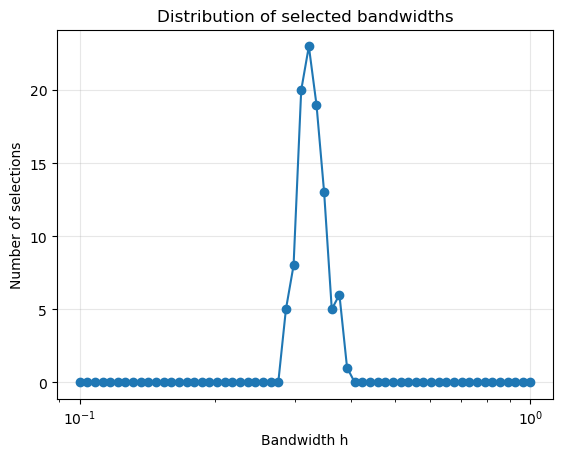

In [56]:
plt.plot(
    h_grid,
    counts,
    marker="o",
)

plt.xscale("log")
plt.xlabel("Bandwidth h")
plt.ylabel("Number of selections")
plt.title("Distribution of selected bandwidths")
plt.grid(alpha=0.3)
plt.show()

In [57]:
n_values = np.arange(100, 1001, 100)

M = 20  # pilot value; increase later
sigma2 = 1.0
tau = 100.0
base_seed = 50_000

counts_by_n = {}

for position, n_value in enumerate(n_values):
    print(f"Running n = {n_value}")

    counts_by_n[n_value] = exact_beta2_bandwidth_selection_counts(
        n=int(n_value),
        h_grid=h_grid,
        M=M,
        sigma2=sigma2,
        tau=tau,
        seed=base_seed + position,
    )

Running n = 100
Running n = 200
Running n = 300
Running n = 400
Running n = 500
Running n = 600
Running n = 700
Running n = 800
Running n = 900
Running n = 1000


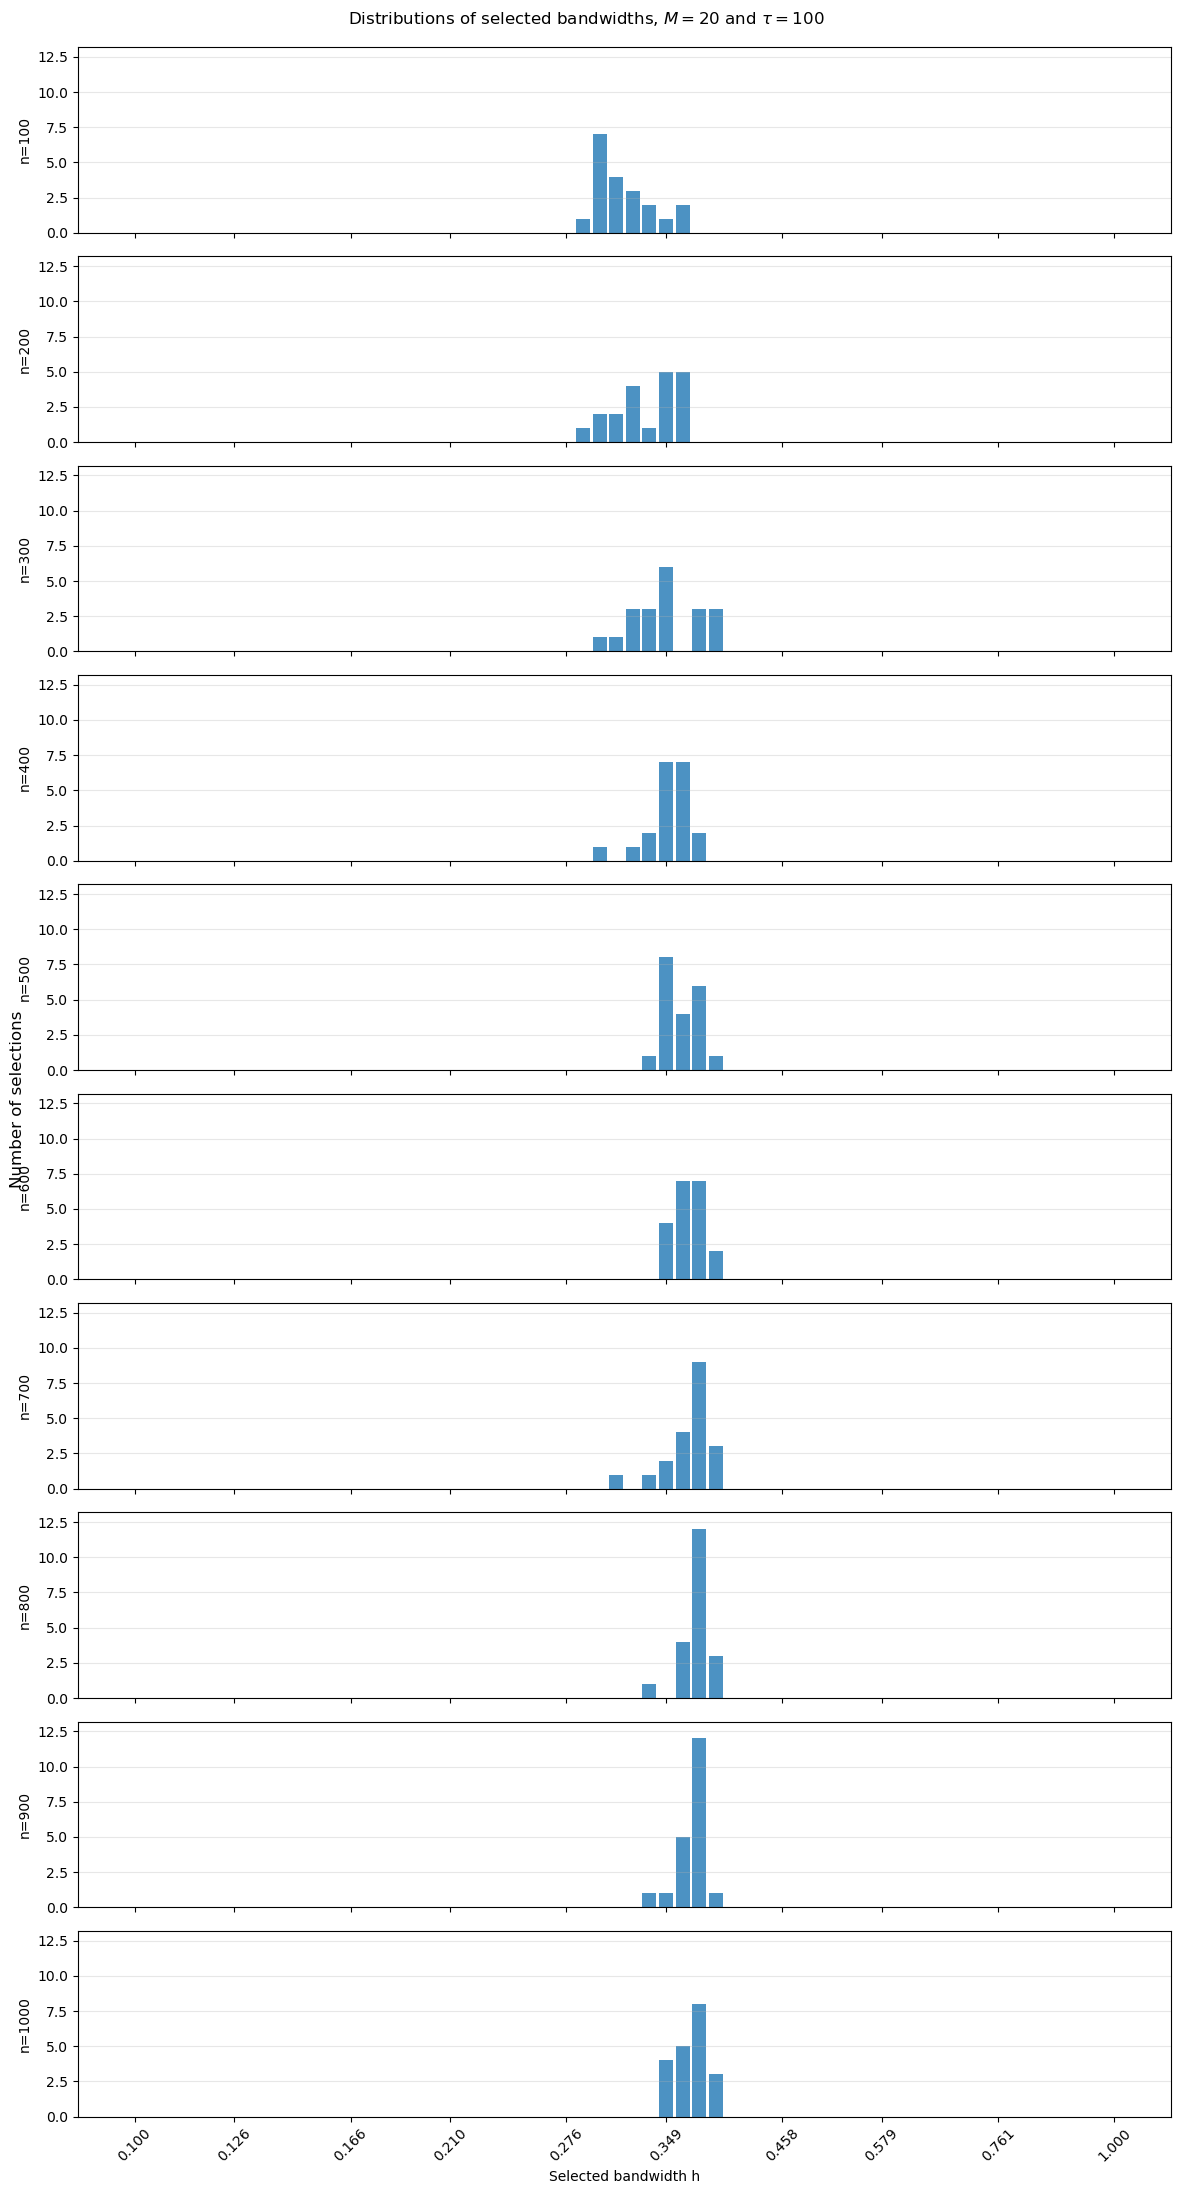

In [58]:
n_values = np.arange(100, 1001, 100)

fig, axes = plt.subplots(
    nrows=len(n_values),
    ncols=1,
    figsize=(12, 22),
    sharex=True,
    sharey=True,
)

bandwidth_positions = np.arange(len(h_grid))
maximum_count = max(counts.max() for counts in counts_by_n.values())

for ax, n_value in zip(axes, n_values):
    counts = counts_by_n[n_value]

    ax.bar(
        bandwidth_positions,
        counts,
        width=0.85,
        color="tab:blue",
        alpha=0.8,
    )

    ax.set_ylabel(f"n={n_value}")
    ax.set_ylim(0, maximum_count * 1.1)
    ax.grid(axis="y", alpha=0.3)

# Show only a manageable number of bandwidth labels.
tick_indices = np.linspace(
    0,
    len(h_grid) - 1,
    10,
    dtype=int,
)

axes[-1].set_xticks(tick_indices)
axes[-1].set_xticklabels(
    [f"{h_grid[index]:.3f}" for index in tick_indices],
    rotation=45,
)
axes[-1].set_xlabel("Selected bandwidth h")

fig.supylabel("Number of selections", x=0.02)
fig.suptitle(
    rf"Distributions of selected bandwidths, $M={M}$ and $\tau={tau:g}$",
    y=0.995,
)

plt.tight_layout()
plt.show()

In [59]:
def quadrature_beta2_bandwidth_selection_counts(
    n,
    h_grid,
    M,
    sigma2=1.0,
    tau=1.0,
    m_x=1_001,
    padding=6.0,
    seed=None,
):
    h_grid = np.asarray(h_grid, dtype=float)
    rng = np.random.default_rng(seed)

    counts = np.zeros(len(h_grid), dtype=int)

    for repetition in range(M):
        samples = rng.normal(
            loc=0.0,
            scale=np.sqrt(sigma2),
            size=n,
        )

        # Spatial grid for numerical integration
        left = samples.min() - padding * h_grid.max()
        right = samples.max() + padding * h_grid.max()
        x_grid = np.linspace(left, right, m_x)

        # Evaluate every KDE on x_grid
        density_values = np.empty(
            (len(h_grid), len(x_grid)),
            dtype=float,
        )

        differences = x_grid[None, :] - samples[:, None]

        for j, h in enumerate(h_grid):
            z = differences / h

            density_values[j] = (
                np.exp(-0.5 * z**2).mean(axis=0)
                / (np.sqrt(2.0 * np.pi) * h)
            )

        # Trapezoidal integration weights
        steps = np.diff(x_grid)
        weights = np.empty_like(x_grid)

        weights[0] = steps[0] / 2.0
        weights[-1] = steps[-1] / 2.0
        weights[1:-1] = (
            steps[:-1] + steps[1:]
        ) / 2.0

        # Quadrature Gram matrix:
        # gram[i,j] = integral f_hat_hi(x) f_hat_hj(x) dx
        gram = (
            density_values * weights[None, :]
        ) @ density_values.T

        diagonal = np.diag(gram)

        l2_squared = np.maximum(
            diagonal[:, None]
            + diagonal[None, :]
            - 2.0 * gram,
            0.0,
        )

        # D_2 = 1/2 ||f_hat_hi - f_hat_hj||_2^2
        D2_quadrature = 0.5 * l2_squared
        np.fill_diagonal(D2_quadrature, 0.0)

        # Similarity matrix
        similarity = np.exp(
            -tau * D2_quadrature
        )
        np.fill_diagonal(similarity, 1.0)

        # Perron vector
        eigenvalues, eigenvectors = np.linalg.eigh(
            similarity
        )

        vector = eigenvectors[
            :,
            int(np.argmax(eigenvalues)),
        ]

        if vector.sum() < 0:
            vector = -vector

        vector = vector / vector.sum()

        # Chosen bandwidth index
        selected_index = int(np.argmax(vector))
        counts[selected_index] += 1

    return counts

In [66]:
n_values = np.arange(100, 1001, 100)

M = 200
sigma2 = 1.0
tau = 1.0
m_x = 1_001
base_seed = 50_000

counts_by_n = {}

for position, n_value in enumerate(n_values):
    print(f"Running n = {n_value}")

    counts_by_n[n_value] = (
        quadrature_beta2_bandwidth_selection_counts(
            n=int(n_value),
            h_grid=h_grid,
            M=M,
            sigma2=sigma2,
            tau=tau,
            m_x=m_x,
            seed=base_seed + position,
        )
    )

Running n = 100


KeyboardInterrupt: 

In [67]:
from kde_tools.fourier import beta2_similarity_matrix_fft

In [68]:
def fourier_beta2_bandwidth_selection_counts(
    n,
    h_grid,
    M,
    sigma2=1.0,
    tau=1.0,
    half_width=12.0,
    spatial_points=2_048,
    seed=None,
):
    h_grid = np.asarray(h_grid, dtype=float)
    rng = np.random.default_rng(seed)

    counts = np.zeros(len(h_grid), dtype=int)

    for repetition in range(M):
        samples = rng.normal(
            loc=0.0,
            scale=np.sqrt(sigma2),
            size=n,
        )

        similarity = beta2_similarity_matrix_fft(
            samples=samples,
            h_grid=h_grid,
            tau=tau,
            half_width=half_width,
            spatial_points=spatial_points,
        )

        vector = perron_vector(similarity)
        selected_index = int(np.argmax(vector))

        counts[selected_index] += 1

    return counts

In [73]:
n_values = np.arange(100, 1001, 100)

M = 200
sigma2 = 1.0
tau = 1.0

half_width = 12.0
spatial_points = 2_048

base_seed = 50_000

counts_by_n_fourier = {}

for position, n_value in enumerate(n_values):
    print(f"Running n = {n_value}")

    counts_by_n_fourier[n_value] = (
        fourier_beta2_bandwidth_selection_counts(
            n=int(n_value),
            h_grid=h_grid,
            M=M,
            sigma2=sigma2,
            tau=tau,
            half_width=half_width,
            spatial_points=spatial_points,
            seed=base_seed + position,
        )
    )

Running n = 100
Running n = 200
Running n = 300
Running n = 400
Running n = 500
Running n = 600
Running n = 700
Running n = 800
Running n = 900
Running n = 1000


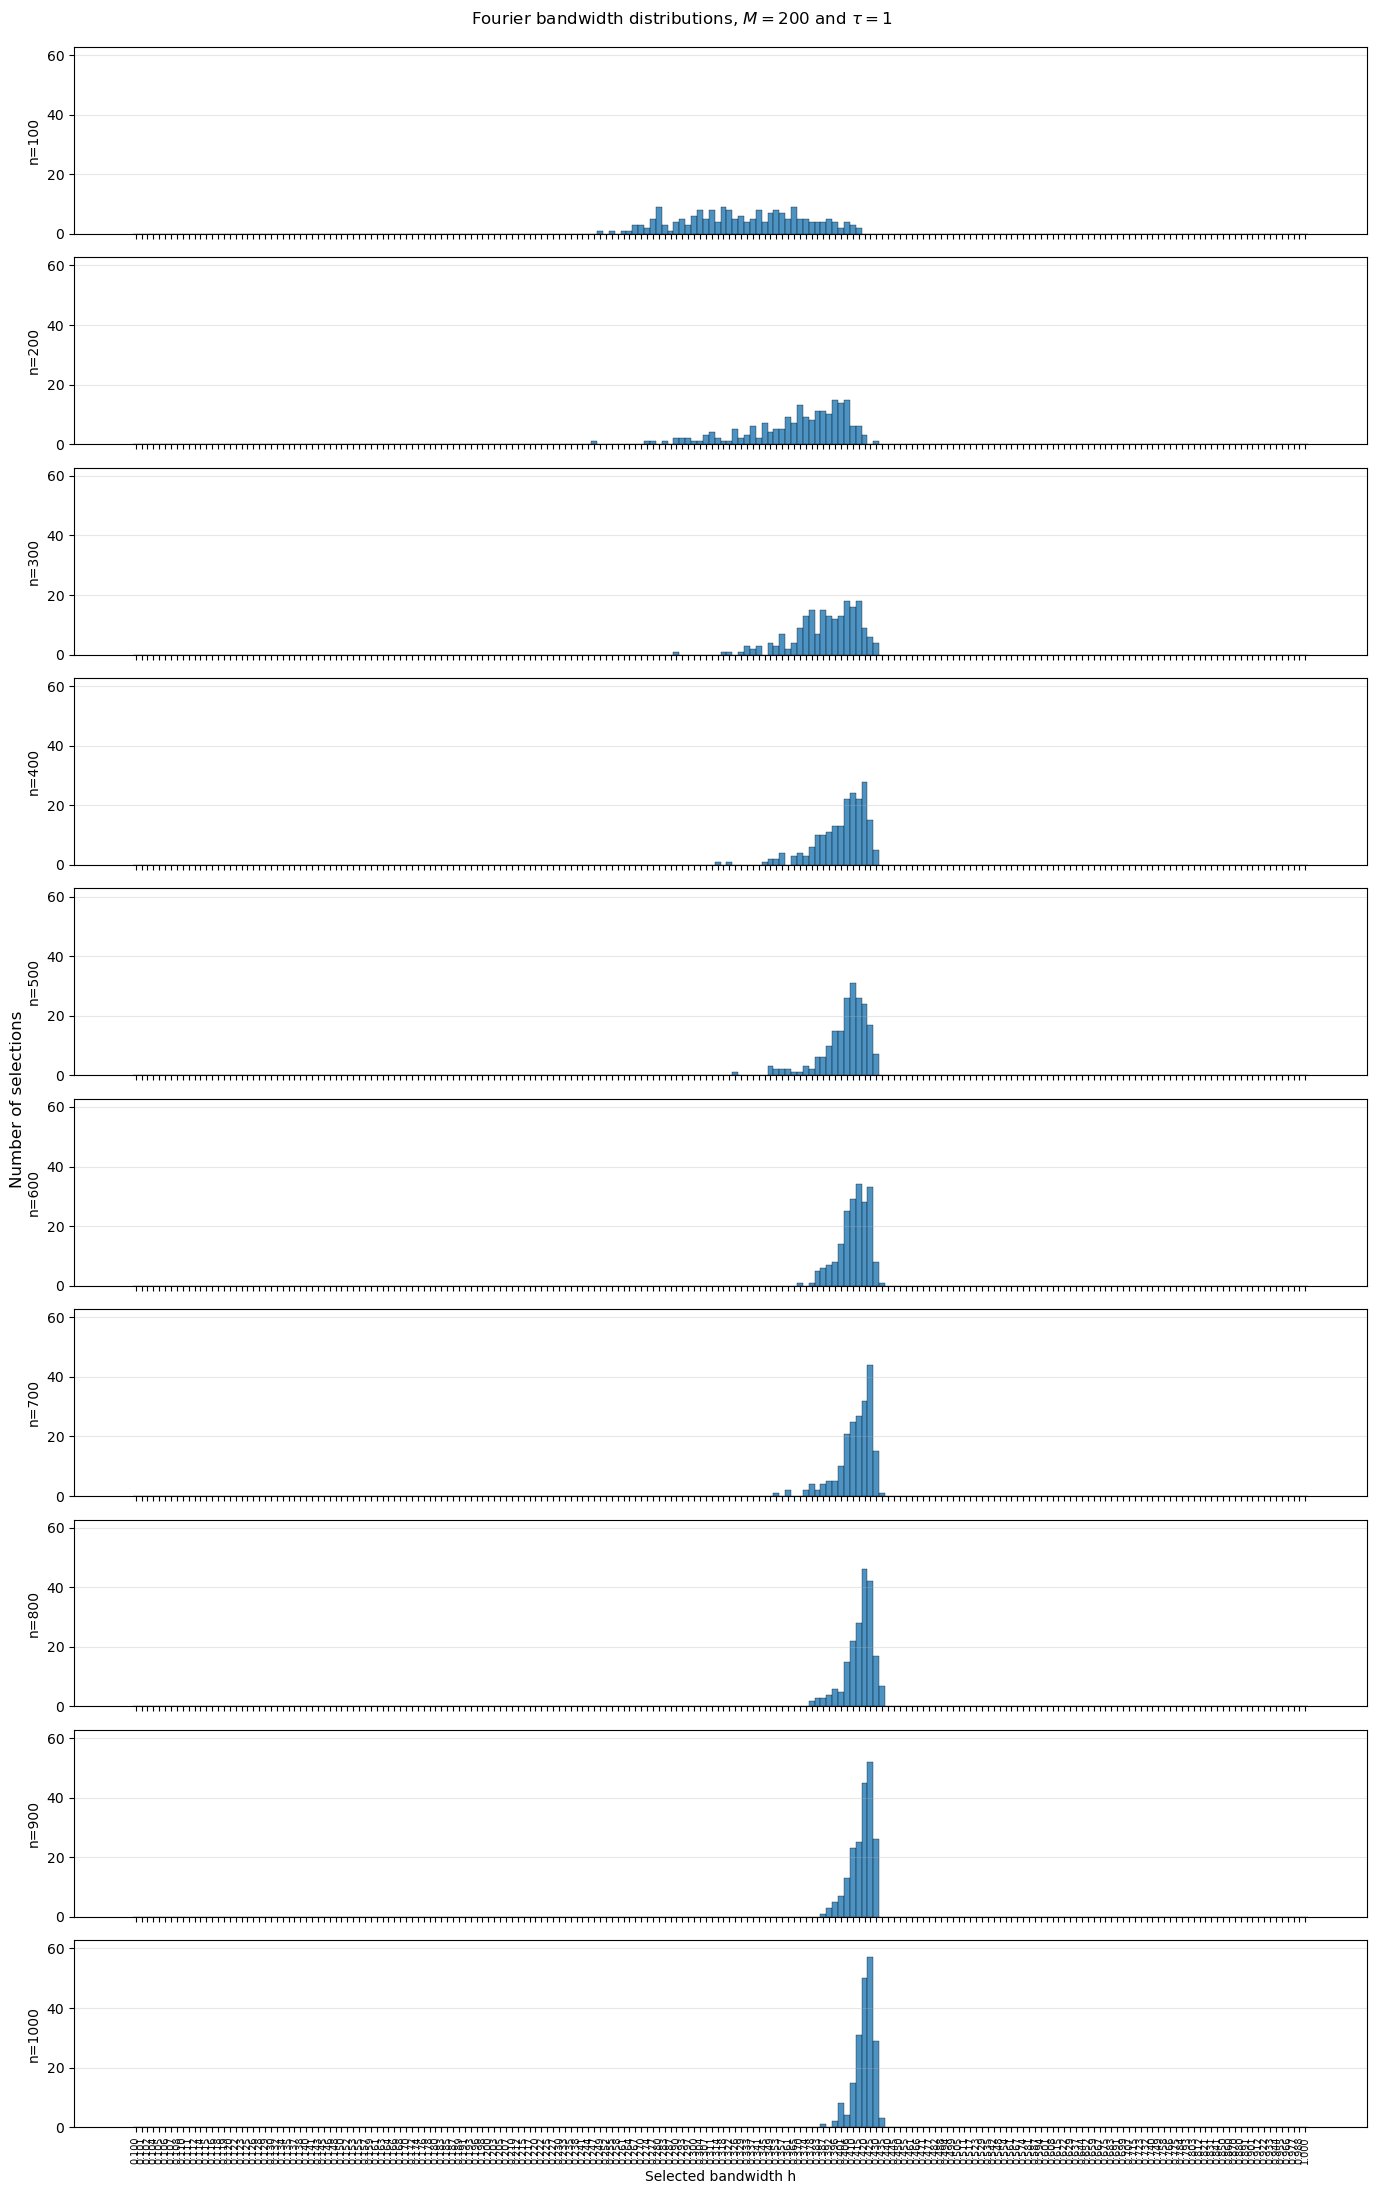

In [74]:
fig, axes = plt.subplots(
    nrows=len(n_values),
    ncols=1,
    figsize=(14, 22),
    sharex=True,
    sharey=True,
)

positions = np.arange(len(h_grid))

maximum_count = max(
    counts.max()
    for counts in counts_by_n_fourier.values()
)

for ax, n_value in zip(axes, n_values):
    counts = counts_by_n_fourier[n_value]

    ax.bar(
        positions,
        counts,
        width=1.0,
        color="tab:blue",
        edgecolor="black",
        linewidth=0.3,
        alpha=0.8,
    )

    ax.set_ylabel(f"n={n_value}")
    ax.set_ylim(0, maximum_count * 1.1)
    ax.grid(axis="y", alpha=0.3)

# Label every bandwidth bin
axes[-1].set_xticks(positions)
axes[-1].set_xticklabels(
    [f"{h:.3f}" for h in h_grid],
    rotation=90,
    fontsize=7,
)

axes[-1].set_xlabel("Selected bandwidth h")

fig.supylabel(
    "Number of selections",
    x=0.02,
)

fig.suptitle(
    rf"Fourier bandwidth distributions, "
    rf"$M={M}$ and $\tau={tau:g}$",
    y=0.995,
)

plt.tight_layout()
plt.show()

ValueError: max() iterable argument is empty

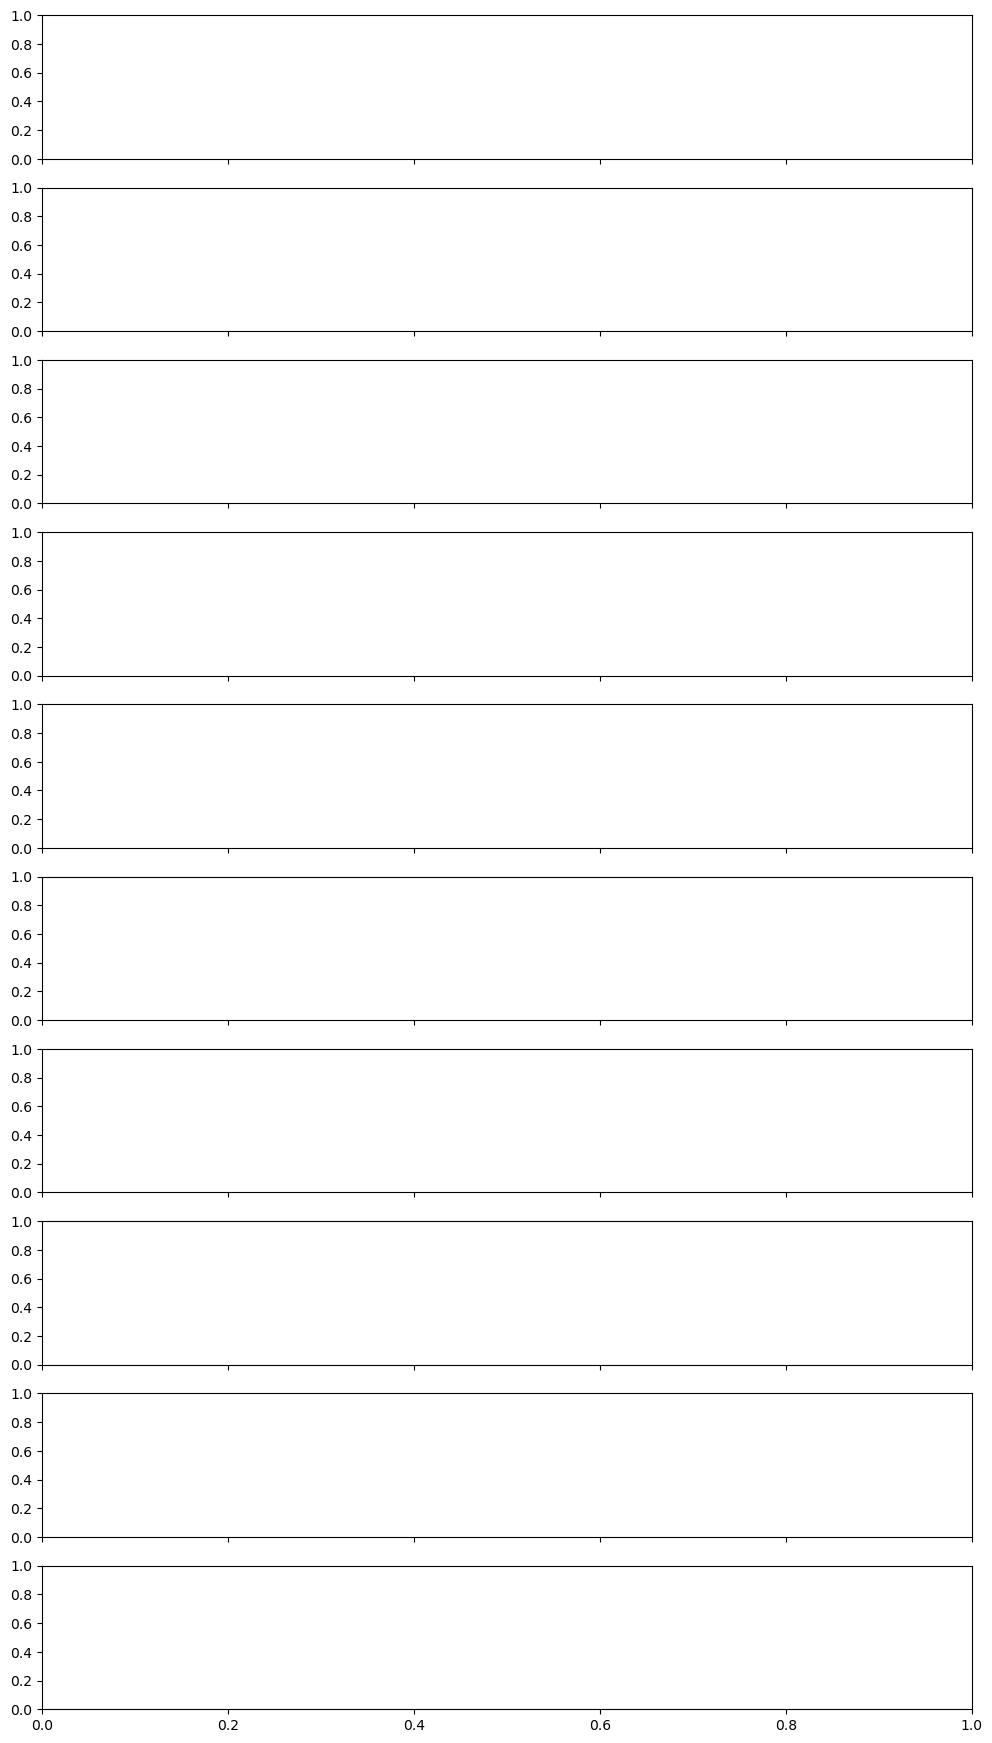

In [70]:
fig, axes = plt.subplots(
    nrows=len(n_values),
    ncols=1,
    figsize=(12, 22),
    sharex=True,
    sharey=True,
)

positions = np.arange(len(h_grid))

maximum_count = max(
    counts.max()
    for counts in counts_by_n.values()
)

for ax, n_value in zip(axes, n_values):
    counts = counts_by_n[n_value]

    ax.bar(
        positions,
        counts,
        width=0.85,
        color="tab:blue",
        alpha=0.8,
    )

    ax.set_ylabel(f"n={n_value}")
    ax.set_ylim(0, maximum_count * 1.1)
    ax.grid(axis="y", alpha=0.3)

tick_indices = np.linspace(
    0,
    len(h_grid) - 1,
    10,
    dtype=int,
)

axes[-1].set_xticks(tick_indices)
axes[-1].set_xticklabels(
    [
        f"{h_grid[index]:.3f}"
        for index in tick_indices
    ],
    rotation=45,
)

axes[-1].set_xlabel("Selected bandwidth h")

fig.supylabel(
    "Number of selections",
    x=0.02,
)

fig.suptitle(
    rf"Quadrature bandwidth distributions, "
    rf"$M={M}$ and $\tau={tau:g}$",
    y=0.995,
)

plt.tight_layout()
plt.show()

ValueError: max() iterable argument is empty

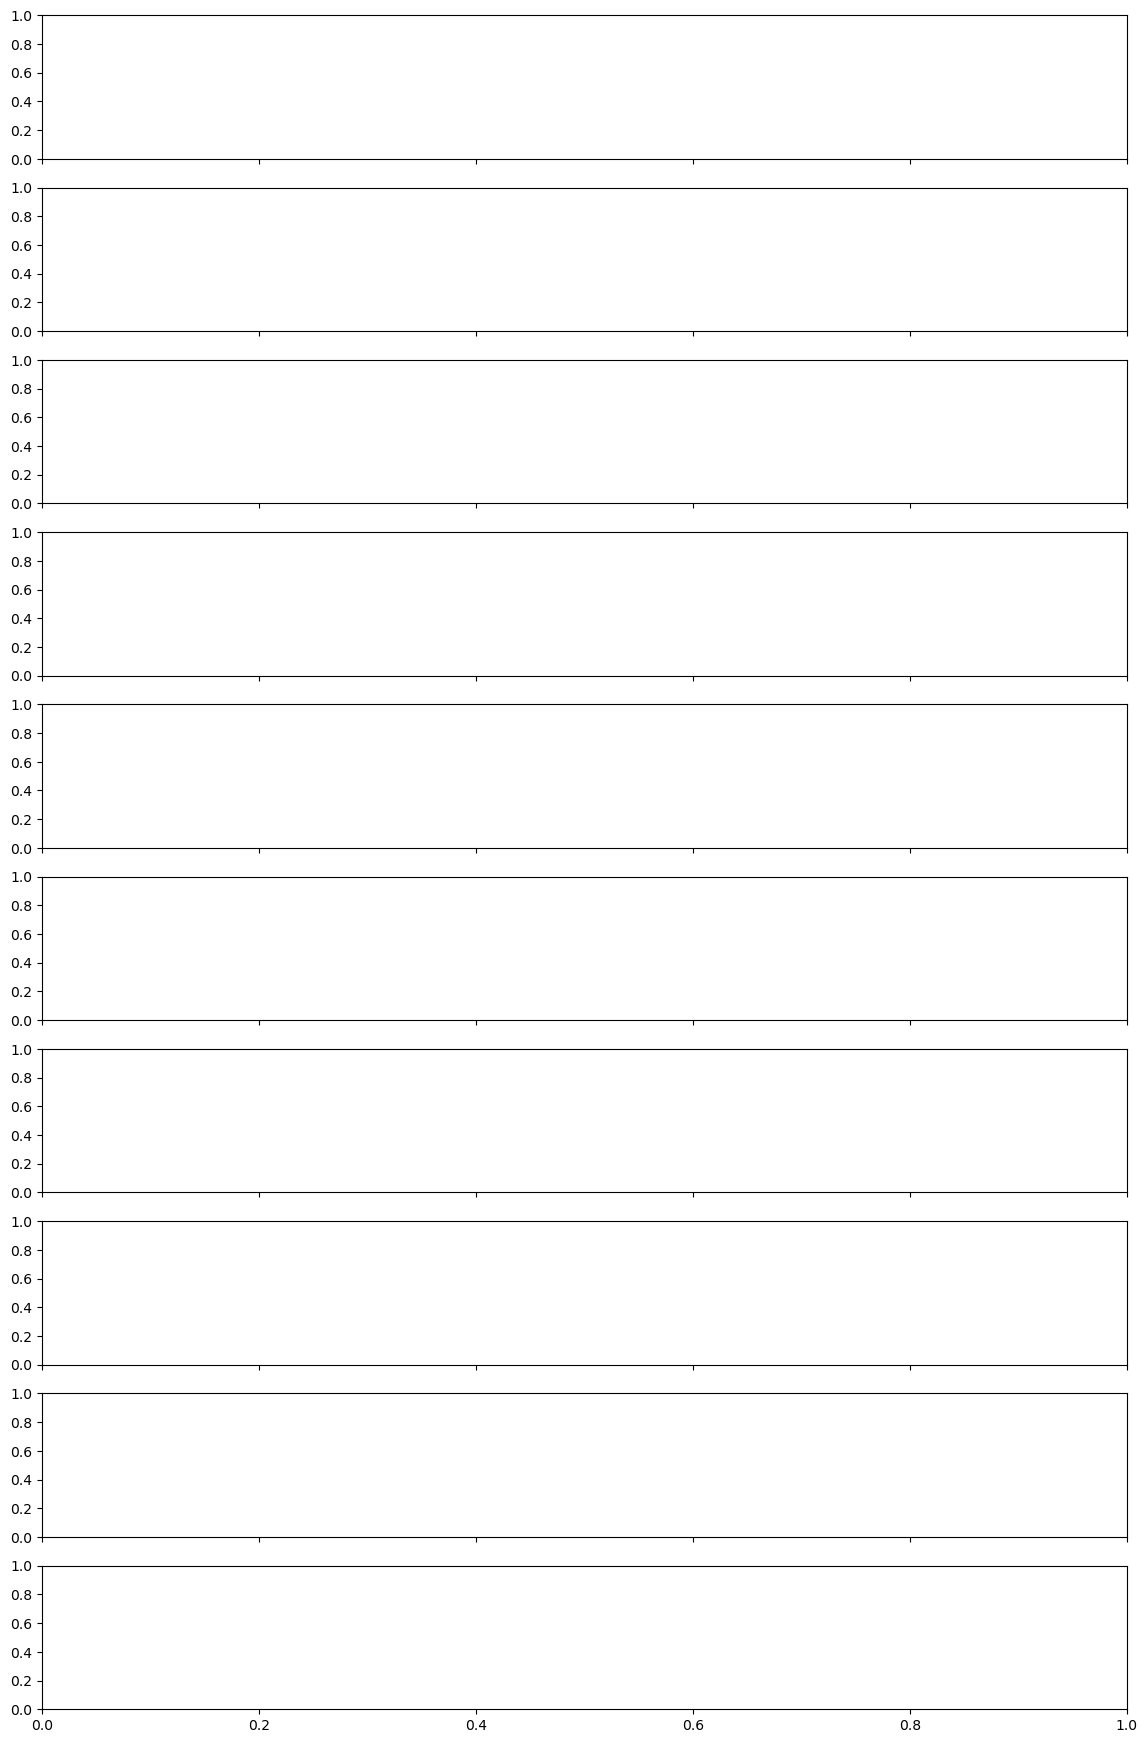

In [71]:
fig, axes = plt.subplots(
    nrows=len(n_values),
    ncols=1,
    figsize=(14, 22),
    sharex=True,
    sharey=True,
)

positions = np.arange(len(h_grid))

maximum_count = max(
    counts.max()
    for counts in counts_by_n.values()
)

for ax, n_value in zip(axes, n_values):
    counts = counts_by_n[n_value]

    ax.bar(
        positions,
        counts,
        width=1.0,
        color="tab:blue",
        edgecolor="black",
        linewidth=0.3,
        alpha=0.8,
    )

    ax.set_ylabel(f"n={n_value}")
    ax.set_ylim(0, maximum_count * 1.1)
    ax.grid(axis="y", alpha=0.3)

# One tick label for every bandwidth
axes[-1].set_xticks(positions)
axes[-1].set_xticklabels(
    [f"{h:.3f}" for h in h_grid],
    rotation=90,
    fontsize=7,
)

axes[-1].set_xlabel("Selected bandwidth h")

fig.supylabel("Number of selections", x=0.02)
fig.suptitle(
    rf"Quadrature bandwidth distributions, "
    rf"$M={M}$ and $\tau={tau:g}$",
    y=0.995,
)

plt.tight_layout()
plt.show()